# ShopKart Sales Performance Analysis (2024–2025)

**Role:** Data Analyst (portfolio project)  **Tools:** Python (pandas, matplotlib, seaborn), SQL, Power BI / Excel

## Business problem
ShopKart is an Indian online retailer selling across 6 categories in 15 cities. Revenue grew in 2025, but leadership
feels profit is not keeping pace. The Head of Sales has asked:

1. How are revenue and profit trending, and is there seasonality?
2. Which categories and products actually make money?
3. Are discounts helping or hurting?
4. Which regions and cities are growing fastest?
5. Where are we losing revenue to returns and cancellations, and why?
6. Who are our customers, and how concentrated is revenue?

**Data:** ~10.9K raw order lines, Jan 2024 – Dec 2025 (cleaned in `scripts/clean_data.py`).
*Revenue* = net sales (after discount) of **delivered** orders only. Amounts are in ₹; 1 lakh = ₹1,00,000.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option('display.float_format', '{:,.2f}'.format)
BLUE, ORANGE, GREY, INK = '#2a78d6', '#eb6834', '#9a9893', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#c9c8c3', 'axes.labelcolor': INK, 'xtick.color': INK,
                     'ytick.color': INK, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
                     'axes.grid': True, 'grid.color': '#ecebe7', 'axes.axisbelow': True,
                     'font.size': 10})
lakh = mtick.FuncFormatter(lambda x, _: f'₹{x/1e5:,.0f}L')

df = pd.read_csv('../data/processed/shopkart_sales_clean.csv', parse_dates=['order_date'])
print(df.shape)
df.head()

(10717, 33)


,order_id,order_date,customer_id,gender,customer_age,city,state,region,product_id,product_name,category,sub_category,quantity,unit_price,unit_cost,discount_pct,payment_method,order_status,delivery_days,customer_rating,gross_sales,discount_amount,net_sales,total_cost,profit,revenue,realised_profit,year,month,year_month,day_of_week,age_group,discount_band
0,ORD500017,2024-01-01,C13090,Female,29.00,Mumbai,Maharashtra,West,P1031,Badminton Racket Pair,Sports,Racket Sports,1,1311,753,0.10,UPI,Delivered,4.00,3.00,1311,131.10,"1,179.90",753,426.90,"1,179.90",426.90,2024,1,2024-01,Monday,25-34,1-10%
1,ORD500221,2024-01-01,C13053,Female,18.00,Lucknow,Uttar Pradesh,North,P1012,Slim Fit Jeans,Fashion,Bottomwear,2,1273,624,0.10,Credit Card,Delivered,5.00,5.00,2546,254.60,"2,291.40",1248,"1,043.40","2,291.40","1,043.40",2024,1,2024-01,Monday,18-24,1-10%
2,ORD500076,2024-01-01,C11696,Male,26.00,Kolkata,West Bengal,East,P1014,Casual Sneakers,Fashion,Footwear,1,1945,950,0.10,Debit Card,Delivered,6.00,4.00,1945,194.50,"1,750.50",950,800.50,"1,750.50",800.50,2024,1,2024-01,Monday,25-34,1-10%
3,ORD500128,2024-01-01,C12968,Male,27.00,Delhi,Delhi,North,P1018,LED Table Lamp,Home & Kitchen,Decor,2,792,463,0.05,UPI,Delivered,6.00,4.00,1584,79.20,"1,504.80",926,578.80,"1,504.80",578.80,2024,1,2024-01,Monday,25-34,1-10%
4,ORD500121,2024-01-01,C10237,Male,33.00,Mumbai,Maharashtra,West,P1012,Slim Fit Jeans,Fashion,Bottomwear,1,1293,624,0.20,Debit Card,Delivered,5.00,5.00,1293,258.60,"1,034.40",624,410.40,"1,034.40",410.40,2024,1,2024-01,Monday,25-34,11-20%


## 1. Data quality check (after cleaning)

In [2]:
print(open('../data/processed/cleaning_log.txt', encoding='utf-8').read())
print()
print('Missing values remaining:')
print(df.isna().sum()[df.isna().sum() > 0])

Raw rows: 10,892
[1] Removed 160 exact duplicate rows
[2] Parsed dates; unparseable left: 0
[3] Standardised city names -> 15 cities; payment methods -> ['Cash on Delivery', 'Credit Card', 'Debit Card', 'Net Banking', 'UPI', 'Wallet']
[4] Removed currency symbols/commas and converted numeric columns
[5] Filled 107 missing regions using state -> region lookup
[6a] Dropped 15 rows with quantity <= 0 (data-entry errors)
[6b] Set 12 impossible ages to null, then filled age/gender from the same customer's other orders; ages still missing: 27
[7] Added gross_sales, discount_amount, net_sales, total_cost, profit, revenue, realised_profit, date parts, age_group, discount_band
Clean rows: 10,717  ->  data/processed/shopkart_sales_clean.csv

Missing values remaining:
customer_age        27
delivery_days      430
customer_rating    430
dtype: int64


`delivery_days` is empty only for cancelled orders and `customer_rating` only for cancelled orders — that is expected, not a data problem.
The 27 remaining missing ages belong to customers who never gave an age on any order; their `age_group` is labelled "Unknown".

## 2. Headline KPIs

In [3]:
delivered = df[df.order_status == 'Delivered']
kpi = pd.Series({
    'Total orders': len(df),
    'Customers': df.customer_id.nunique(),
    'Revenue (₹ lakh)': df.revenue.sum() / 1e5,
    'Profit (₹ lakh)': df.realised_profit.sum() / 1e5,
    'Profit margin %': 100 * df.realised_profit.sum() / df.revenue.sum(),
    'Avg order value (₹)': delivered.revenue.mean(),
    'Revenue lost to returns/cancellations (₹ lakh)': df.loc[df.order_status != 'Delivered', 'net_sales'].sum() / 1e5,
})
kpi.to_frame('value')

,value
Total orders,"10,717.00"
Customers,"2,739.00"
Revenue (₹ lakh),629.42
Profit (₹ lakh),75.56
Profit margin %,12.01
Avg order value (₹),"6,640.88"
Revenue lost to returns/cancellations (₹ lakh),74.38


In [4]:
yearly = df.groupby('year')[['revenue', 'realised_profit']].sum()
yearly['margin_%'] = 100 * yearly.realised_profit / yearly.revenue
yearly['revenue_growth_%'] = 100 * yearly.revenue.pct_change()
yearly

,revenue,realised_profit,margin_%,revenue_growth_%
year,,,,
2024,"28,457,453.25","3,430,585.25",12.06,NaN
2025,"34,484,846.70","4,125,850.70",11.96,21.18


## 3. Revenue trend & seasonality

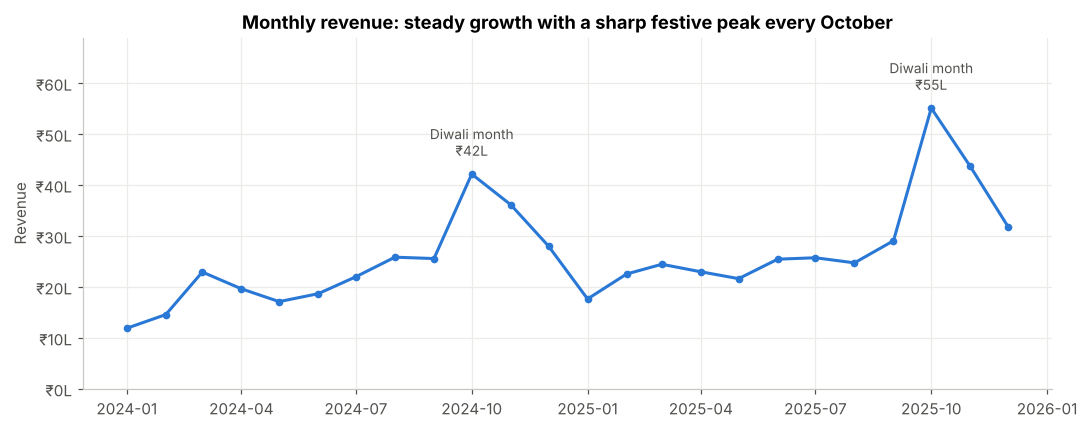

In [5]:
monthly = df.groupby(df.order_date.dt.to_period('M'))['revenue'].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, color=BLUE, lw=2, marker='o', ms=4)
for ts in [pd.Timestamp('2024-10-01'), pd.Timestamp('2025-10-01')]:
    ax.annotate(f'Diwali month\n₹{monthly[ts]/1e5:.0f}L', (ts, monthly[ts]), xytext=(0, 12),
                textcoords='offset points', ha='center', fontsize=9, color=INK)
ax.yaxis.set_major_formatter(lakh)
ax.set_ylim(0, monthly.max() * 1.25)
ax.set_title('Monthly revenue: steady growth with a sharp festive peak every October')
ax.set_ylabel('Revenue')
plt.tight_layout(); plt.savefig('../images/01_monthly_revenue.png', bbox_inches='tight'); plt.show()

In [6]:
season = df.groupby('month')['revenue'].sum()
share = (100 * season / season.sum()).round(1)
print('Share of total revenue by calendar month (%):')
print(share.to_string())
print(f"\nOct + Nov = {share[10] + share[11]:.1f}% of annual revenue in 2 of 12 months")

Share of total revenue by calendar month (%):
month
1     4.70
2     5.90
3     7.50
4     6.80
5     6.20
6     7.00
7     7.60
8     8.00
9     8.70
10   15.50
11   12.70
12    9.50

Oct + Nov = 28.2% of annual revenue in 2 of 12 months


**Insight:** Revenue grew **21% YoY**. October–November (Diwali/festive season) alone bring in ~28% of the year's revenue,
and January is consistently the weakest month. Inventory, staffing and marketing budget should be planned around this peak.

## 4. Category & product profitability

In [7]:
cat = df.groupby('category')[['revenue', 'realised_profit']].sum()
cat['revenue_share_%'] = 100 * cat.revenue / cat.revenue.sum()
cat['profit_share_%'] = 100 * cat.realised_profit / cat.realised_profit.sum()
cat['margin_%'] = 100 * cat.realised_profit / cat.revenue
cat = cat.sort_values('revenue', ascending=False)
cat

,revenue,realised_profit,revenue_share_%,profit_share_%,margin_%
category,,,,,
Electronics,"40,537,421.05","394,146.05",64.40,5.22,0.97
Fashion,"7,017,716.65","2,990,902.65",11.15,39.58,42.62
Furniture,"5,800,916.30","1,238,425.30",9.22,16.39,21.35
Home & Kitchen,"4,839,637.10","1,163,385.10",7.69,15.40,24.04
Sports,"3,369,468.70","1,049,854.70",5.35,13.89,31.16
Beauty,"1,377,140.15","719,722.15",2.19,9.52,52.26


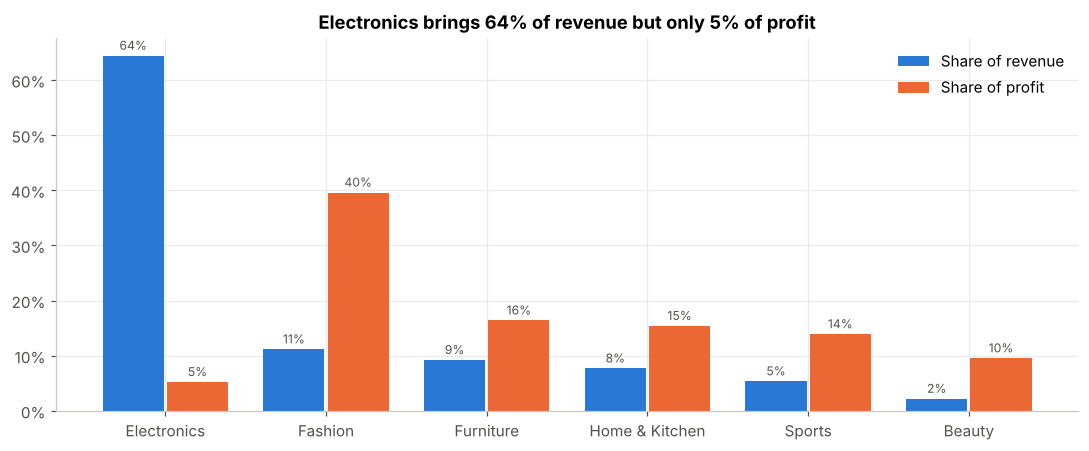

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(cat)); w = 0.38
b1 = ax.bar(x - w/2 - 0.01, cat['revenue_share_%'], w, color=BLUE, label='Share of revenue')
b2 = ax.bar(x + w/2 + 0.01, cat['profit_share_%'], w, color=ORANGE, label='Share of profit')
ax.bar_label(b1, fmt='%.0f%%', fontsize=8, color=INK, padding=2)
ax.bar_label(b2, fmt='%.0f%%', fontsize=8, color=INK, padding=2)
ax.set_xticks(x, cat.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Electronics brings 64% of revenue but only 5% of profit')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('../images/02_category_share.png', bbox_inches='tight'); plt.show()

In [9]:
prod = (df.groupby(['product_name', 'category'])[['revenue', 'realised_profit']].sum()
          .assign(margin_pct=lambda d: 100 * d.realised_profit / d.revenue)
          .sort_values('realised_profit'))
print('Bottom 5 products by profit:')
display(prod.head(5))
print('Top 5 products by profit:')
prod.tail(5).iloc[::-1]

Bottom 5 products by profit:


,,revenue,realised_profit,margin_pct
product_name,category,,,
iPhone 15,Electronics,"9,203,108.35","-296,301.65",-3.22
HP Pavilion 15,Electronics,"8,132,698.55","-165,513.45",-2.04
Lenovo IdeaPad Slim 3,Electronics,"7,091,789.30","-31,106.70",-0.44
Samsung Galaxy M34,Electronics,"3,397,748.60","29,350.60",0.86
Redmi Note 13,Electronics,"3,869,933.90","52,734.90",1.36


Top 5 products by profit:


,,revenue,realised_profit,margin_pct
product_name,category,,,
Silk Saree,Fashion,"1,881,019.40","717,748.40",38.16
Running Shoes,Fashion,"1,499,773.15","625,546.15",41.71
Casual Sneakers,Fashion,"1,170,416.95","515,866.95",44.08
3-Seater Sofa,Furniture,"2,355,019.00","447,125.00",18.99
Slim Fit Jeans,Fashion,"940,951.35","436,135.35",46.35


**Insight:** Electronics is a *revenue* engine, not a *profit* engine — its 1% margin is wiped out by discounts.
iPhone 15, HP Pavilion and Lenovo IdeaPad **lose money overall**. Fashion (43% margin) and Beauty (52%) are the real profit drivers:
Fashion is only 11% of revenue but 40% of profit.

## 5. Are discounts helping or hurting?

In [10]:
order = ['No discount', '1-10%', '11-20%', '21-30%', '>30%']
disc = (df.groupby('discount_band').agg(orders=('order_id', 'count'), revenue=('revenue', 'sum'),
                                        profit=('realised_profit', 'sum'))
          .reindex(order))
disc['margin_%'] = 100 * disc.profit / disc.revenue
disc

,orders,revenue,profit,margin_%
discount_band,,,,
No discount,2759,"17,999,516.00","4,080,922.00",22.67
1-10%,4234,"25,100,041.15","3,935,681.15",15.68
11-20%,2806,"15,629,122.20","983,404.20",6.29
21-30%,186,"902,387.50","-117,615.50",-13.03
>30%,732,"3,311,233.10","-1,325,955.90",-40.04


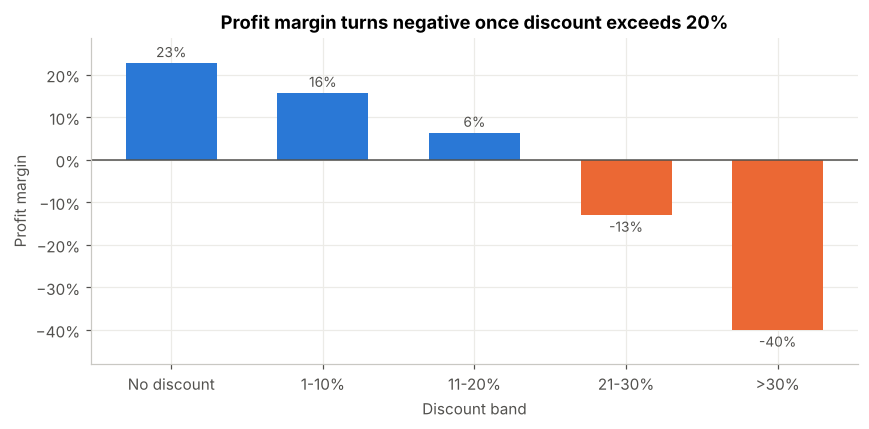

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = [BLUE if v >= 0 else ORANGE for v in disc['margin_%']]
bars = ax.bar(disc.index, disc['margin_%'], color=colors, width=0.6)
ax.bar_label(bars, fmt='%.0f%%', fontsize=9, color=INK, padding=2)
ax.axhline(0, color=INK, lw=1)
ax.set_ylim(disc['margin_%'].min() - 8, disc['margin_%'].max() + 6)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Profit margin turns negative once discount exceeds 20%')
ax.set_xlabel('Discount band'); ax.set_ylabel('Profit margin')
plt.tight_layout(); plt.savefig('../images/03_discount_margin.png', bbox_inches='tight'); plt.show()

In [12]:
deep = df[df.discount_pct > 0.20]
print(f"Orders with >20% discount: {len(deep):,} ({100*len(deep)/len(df):.1f}% of orders)")
print(f"Profit from them: ₹{deep.realised_profit.sum()/1e5:,.2f} lakh")
print('\nDeep-discount loss by category (₹ lakh):')
print((deep.groupby('category').realised_profit.sum() / 1e5).sort_values().round(2).to_string())

Orders with >20% discount: 918 (8.6% of orders)
Profit from them: ₹-14.44 lakh

Deep-discount loss by category (₹ lakh):
category
Electronics      -14.22
Furniture         -0.48
Home & Kitchen    -0.41
Sports            -0.01
Beauty             0.21
Fashion            0.48


**Insight:** Only ~8.6% of orders carry a discount above 20%, yet they **lose ~₹14.4 lakh** — about 19% of the total profit we did make.
Most of that loss is Electronics, where the margin is too thin to absorb any discount. Recommendation: cap Electronics discounts
at ~10% and move festive deep discounts to high-margin Fashion and Beauty.

## 6. Regional performance

In [13]:
reg = df.pivot_table(index='region', columns='year', values='revenue', aggfunc='sum')
reg['growth_%'] = 100 * (reg[2025] / reg[2024] - 1)
reg.sort_values('growth_%', ascending=False)

year,2024,2025,growth_%
region,,,
South,"9,610,333.10","12,538,249.40",30.47
West,"7,434,415.75","8,808,478.30",18.48
North,"7,462,922.90","8,606,245.85",15.32
East,"3,949,781.50","4,531,873.15",14.74


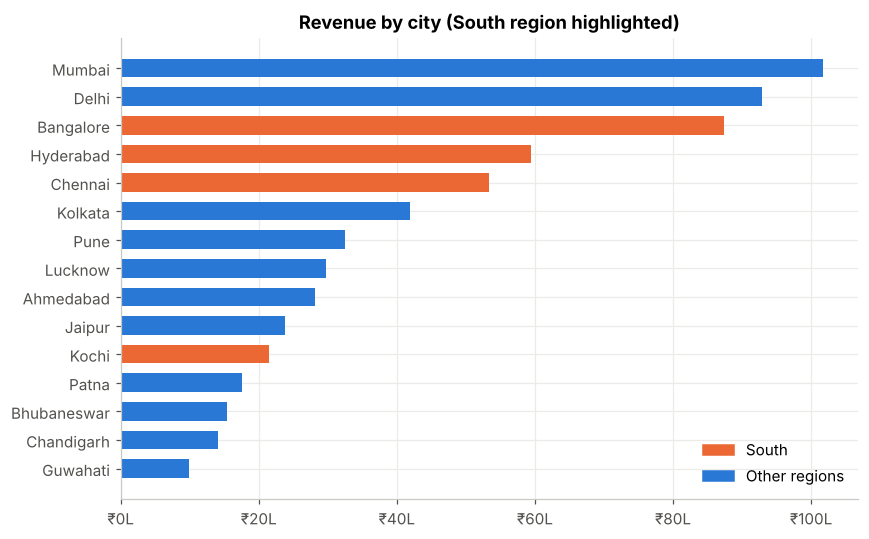

In [14]:
city = df.groupby(['city', 'region'])['revenue'].sum().sort_values().reset_index()
fig, ax = plt.subplots(figsize=(8, 5))
c = [ORANGE if r == 'South' else BLUE for r in city.region]
ax.barh(city.city, city.revenue, color=c, height=0.65)
ax.xaxis.set_major_formatter(lakh)
ax.set_title('Revenue by city (South region highlighted)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ORANGE, label='South'), Patch(color=BLUE, label='Other regions')], frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('../images/04_city_revenue.png', bbox_inches='tight'); plt.show()

**Insight:** Mumbai, Delhi and Bangalore together make up ~45% of revenue. The **South** is the fastest-growing region (+30% YoY vs ~15–18% elsewhere),
led by Bangalore. The **East** is the smallest and slowest, and also has the longest delivery times (see section 7).

## 7. Returns, cancellations & delivery experience

In [15]:
status = pd.crosstab(df.category, df.order_status, normalize='index').mul(100).round(1)
status.sort_values('Returned', ascending=False)

order_status,Cancelled,Delivered,Returned
category,,,
Fashion,4.70,81.80,13.50
Furniture,3.00,87.90,9.10
Home & Kitchen,2.60,92.20,5.20
Electronics,4.40,90.80,4.80
Sports,3.40,92.30,4.40
Beauty,4.60,92.50,2.90


In [16]:
pay = (df.groupby('payment_method')
         .agg(orders=('order_id', 'count'), cancel_rate=('order_status', lambda s: 100 * (s == 'Cancelled').mean()))
         .sort_values('cancel_rate', ascending=False))
pay

,orders,cancel_rate
payment_method,,
Cash on Delivery,1914,11.44
Net Banking,512,3.52
Credit Card,1982,2.47
Wallet,548,2.37
UPI,4469,2.28
Debit Card,1292,2.24


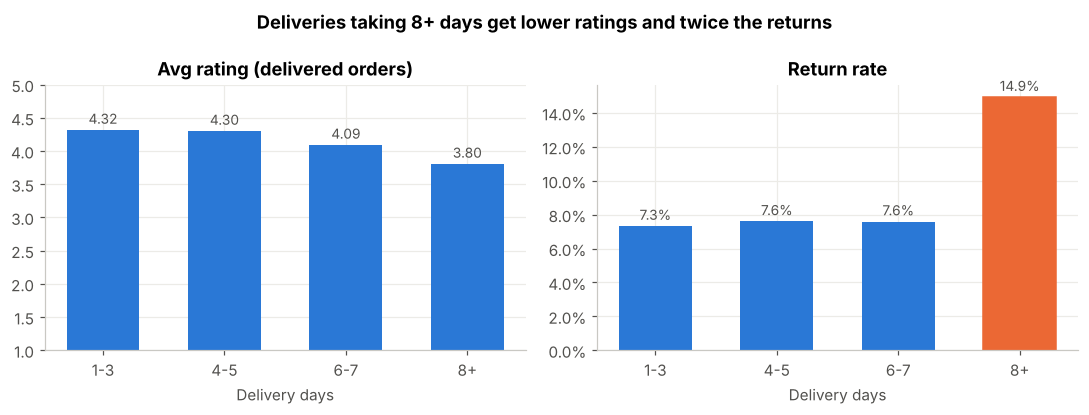

Average delivery days by region:
region
East     6.0
North    4.0
South    4.0
West     4.0


In [17]:
d = df.dropna(subset=['delivery_days']).copy()
d['bucket'] = pd.cut(d.delivery_days, [0, 3, 5, 7, 14], labels=['1-3', '4-5', '6-7', '8+'])
exp = d.groupby('bucket', observed=True).agg(
    avg_rating=('customer_rating', lambda s: s[d.loc[s.index, 'order_status'] == 'Delivered'].mean()),
    return_rate=('order_status', lambda s: 100 * (s == 'Returned').mean()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
b = axes[0].bar(exp.index.astype(str), exp.avg_rating, color=BLUE, width=0.6)
axes[0].bar_label(b, fmt='%.2f', fontsize=9, color=INK, padding=2)
axes[0].set_ylim(1, 5); axes[0].set_title('Avg rating (delivered orders)'); axes[0].set_xlabel('Delivery days')
b = axes[1].bar(exp.index.astype(str), exp.return_rate, color=BLUE, width=0.6)
b[-1].set_color(ORANGE)
axes[1].bar_label(b, fmt='%.1f%%', fontsize=9, color=INK, padding=2)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[1].set_title('Return rate'); axes[1].set_xlabel('Delivery days')
fig.suptitle('Deliveries taking 8+ days get lower ratings and twice the returns', fontweight='bold')
plt.tight_layout(); plt.savefig('../images/05_delivery_experience.png', bbox_inches='tight'); plt.show()
print('Average delivery days by region:')
print(d.groupby('region').delivery_days.mean().map('{:.1f}'.format).to_string())

**Insight:**
- **Fashion has a 13.5% return rate** (likely sizing/fit) — more than double most categories.
- **Cash on Delivery orders are cancelled 11.4% of the time** vs ~2–3% for prepaid methods.
- Orders that take **8+ days** to arrive are returned **twice as often** (14.9% vs ~7.5%) and rated lower. The East averages ~2 days slower than other regions.
- In total ~₹74 lakh of order value (10.6%) was lost to returns and cancellations.

## 8. Customer analysis

Customers: 2,739
Repeat customers (2+ orders): 72.8%
Top 20% of customers generate 70.6% of revenue


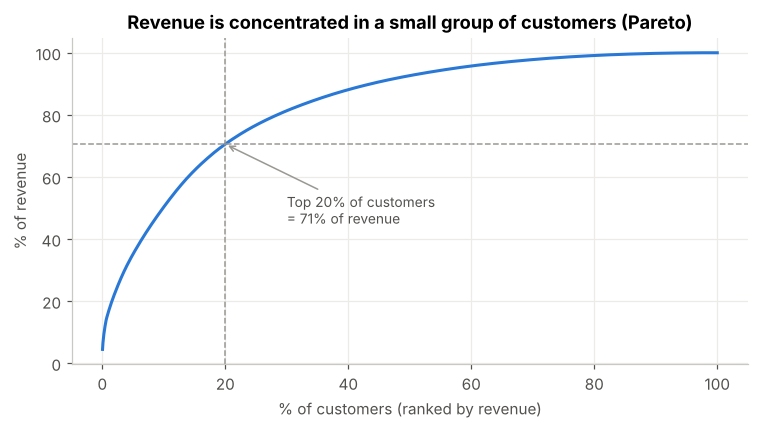

In [18]:
cust = df.groupby('customer_id').agg(orders=('order_id', 'nunique'), revenue=('revenue', 'sum'))
cust_sorted = cust.revenue.sort_values(ascending=False)
top20 = cust_sorted.head(int(len(cust_sorted) * 0.2)).sum() / cust_sorted.sum()
print(f"Customers: {len(cust):,}")
print(f"Repeat customers (2+ orders): {100*(cust.orders > 1).mean():.1f}%")
print(f"Top 20% of customers generate {100*top20:.1f}% of revenue")

cum = cust_sorted.cumsum() / cust_sorted.sum()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color=BLUE, lw=2)
ax.axvline(20, color=GREY, ls='--', lw=1); ax.axhline(top20 * 100, color=GREY, ls='--', lw=1)
ax.annotate(f'Top 20% of customers\n= {top20*100:.0f}% of revenue', (20, top20 * 100), xytext=(30, 45),
            textcoords='data', fontsize=9, color=INK, arrowprops=dict(arrowstyle='->', color=GREY))
ax.set_xlabel('% of customers (ranked by revenue)'); ax.set_ylabel('% of revenue')
ax.set_title('Revenue is concentrated in a small group of customers (Pareto)')
plt.tight_layout(); plt.savefig('../images/06_customer_pareto.png', bbox_inches='tight'); plt.show()

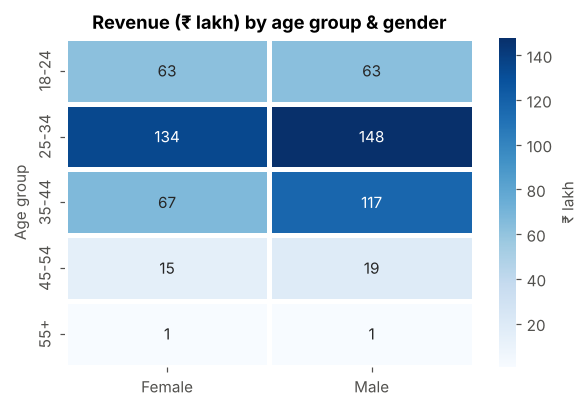

In [19]:
seg = df[(df.gender != 'Unknown') & (df.age_group != 'Unknown')]
pivot = seg.pivot_table(index='age_group', columns='gender', values='revenue', aggfunc='sum') / 1e5
fig, ax = plt.subplots(figsize=(5.5, 3.8))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '₹ lakh'}, linewidths=2, linecolor='white', ax=ax)
ax.set_title('Revenue (₹ lakh) by age group & gender'); ax.set_xlabel(''); ax.set_ylabel('Age group')
plt.tight_layout(); plt.savefig('../images/07_age_gender.png', bbox_inches='tight'); plt.show()

**Insight:** 73% of customers come back, and the **top 20% of customers drive ~70% of revenue** — a loyalty programme for this group is high-value.
The **25–34** age group is the core market (~45% of revenue).

## 9. Summary of findings & recommendations

| # | Finding | Recommendation | Expected impact |
|---|---|---|---|
| 1 | Electronics = 64% of revenue, 5% of profit; 3 laptops/phones lose money | Cap Electronics discounts at ~10%; push accessories & extended warranties | Protect thin margins |
| 2 | Discounts >20% lose ~₹14 lakh (≈19% of profit) | Put festive deep discounts on Fashion/Beauty (40–50% margins) instead | Recover a large part of the loss |
| 3 | Oct–Nov = ~28% of annual revenue | Plan inventory, delivery capacity and ad spend around the festive peak | Avoid stock-outs and delays |
| 4 | South growing 30% YoY | Expand assortment and marketing in Bangalore, Hyderabad, Chennai | Ride the fastest growth |
| 5 | COD cancel rate 11.4% vs ~2–3% prepaid | Offer a small prepaid/UPI incentive; confirm COD orders by call/SMS | Fewer cancellations & failed deliveries |
| 6 | Fashion returns 13.5%; 8+ day deliveries returned 2× | Add size guides & fit reviews; improve East logistics | Lower returns, higher ratings |
| 7 | Top 20% customers = ~70% of revenue | Launch a loyalty tier with early festive access | Retain the most valuable customers |

**Limitations:** The data is synthetic (built to mimic a real retailer), has no marketing-spend or traffic data, and uses product-level cost
rather than fully-loaded cost (shipping, returns handling). With those, the next step would be a proper return-on-discount and CLV analysis.